
# Maximum Likelihood Estimation: A Visual Introduction

Suppose we observe data
$$
x_1,\ldots,x_n \overset{\mathrm{i.i.d.}}{\sim} p_\theta(x),
$$
but the parameter $\theta$ is unknown.

The **method of moments** estimates $\theta$ by matching a few model moments to sample moments.

Maximum likelihood asks a different question:

> **Which parameter value makes the data we actually observed most plausible?**

For independent observations,
$$
L(\theta)
=
\prod_{i=1}^n p_\theta(x_i),
\qquad
\widehat\theta_{\mathrm{MLE}}
=
\arg\max_\theta L(\theta).
$$

We will visualize this idea using
$$
X_i\sim\operatorname{Poisson}(\lambda).
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

np.random.seed(7) # also play with this parameter

# "True" model used only to generate a classroom dataset
lambda_true = 4.0
n = 200
x = np.random.poisson(lambda_true, size=n)

print("Observed data:")
print(x)
print(f"n = {n}")
print(f"sample mean = {x.mean():.3f}")


Observed data:
[5 2 4 5 5 5 5 4 5 6 5 1 7 4 3 8 4 5 7 2 5 3 3 5 5 4 2 0 2 1 3 4 7 2 3 3 4
 5 3 6 7 4 6 4 4 4 7 6 2 6 2 6 3 4 4 3 2 2 2 3 3 8 4 4 3 2 3 4 5 3 5 7 3 3
 4 5 8 4 6 8 4 8 5 4 3 3 4 6 5 2 2 4 1 3 5 5 4 4 4 1 7 2 8 3 7 3 1 1 4 1 1
 3 4 3 6 5 6 3 3 4 5 3 3 4 2 6 2 2 3 5 0 4 5 1 5 4 4 5 2 8 2 4 2 4 4 4 3 5
 9 4 2 3 9 5 3 5 6 2 7 3 4 4 8 6 0 7 3 2 1 4 4 5 4 4 5 5 2 3 6 6 5 5 3 4 4
 3 4 5 6 6 3 5 1 3 4 2 5 1 3 2]
n = 200
sample mean = 4.015



## 1. Same family, different parameter values

Assume we know that the observations are Poisson, but we do **not** know \(\lambda\).

Different values of $x$ produce different probability distributions.  
The data should tell us which one is most plausible.


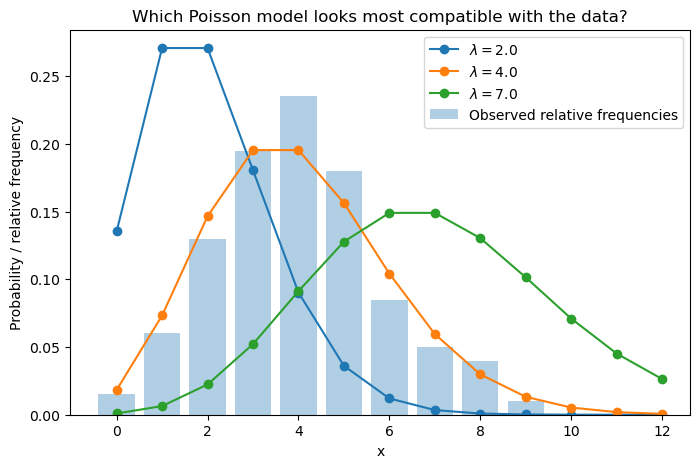

In [2]:

k = np.arange(0, max(13, x.max()+4))
candidate_lambdas = [2.0, 4.0, 7.0]

plt.figure(figsize=(8, 5))

# Empirical distribution of observed counts
values, counts = np.unique(x, return_counts=True)
plt.bar(values, counts / n, alpha=0.35, label="Observed relative frequencies")

for lam in candidate_lambdas:
    plt.plot(k, poisson.pmf(k, lam), marker="o", label=fr"$\lambda={lam}$")

plt.xlabel("x")
plt.ylabel("Probability / relative frequency")
plt.title("Which Poisson model looks most compatible with the data?")
plt.legend()
plt.savefig("mle-motivate.png", dpi=500, bbox_inches="tight")


The visual fit is useful, but maximum likelihood gives a precise criterion.

For a Poisson random variable,
$$
p_\lambda(x_i)
=
\frac{\lambda^{x_i}e^{-\lambda}}{x_i!}.
$$

For independent observations,
$$
L(\lambda)
=
\prod_{i=1}^n
\frac{\lambda^{x_i}e^{-\lambda}}{x_i!}.
$$

Each candidate \(\lambda\) assigns a probability to every observed \(x_i\).  
The likelihood multiplies these contributions across the full dataset.


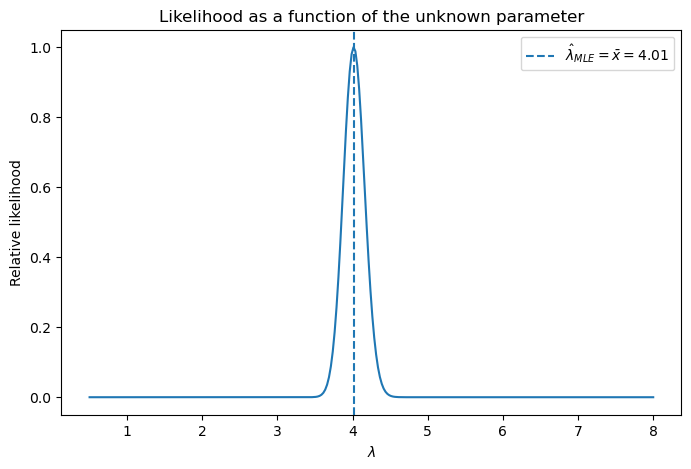

In [3]:
candidate_lambdas = np.linspace(0.5, 8.0, 300)

logL = np.array([
    np.sum(poisson.logpmf(x, mu=lam))
    for lam in candidate_lambdas
])

# Rescale likelihood to avoid numerical underflow and make the shape easy to see.
relative_L = np.exp(logL - logL.max())

lambda_hat = x.mean()

plt.figure(figsize=(8, 5))
plt.plot(candidate_lambdas, relative_L)
plt.axvline(lambda_hat, linestyle="--", label=fr"$\hat\lambda_{{MLE}}=\bar x={lambda_hat:.2f}$")
plt.xlabel(r"$\lambda$")
plt.ylabel("Relative likelihood")
plt.title("Likelihood as a function of the unknown parameter")
plt.legend()
plt.show()



## 2. The data are fixed; the parameter varies

This is the key conceptual switch.

When writing a probability model,
$$
p_\lambda(x),
$$
we often think of $\lambda$ as fixed and \(x\) as random.

Once the data $x_1,\ldots,x_n$ have been observed, they are fixed numbers.  
The likelihood
$$
L(\lambda)
=
p_\lambda(x_1,\ldots,x_n)
$$
is therefore viewed as a **function of $\lambda$**.

The MLE is the value at the peak.


In [4]:

test_lambdas = [2.0, 3.0, 4.0, 5.0, 7.0]

print("Candidate lambda    log-likelihood")
print("-----------------------------------")
for lam in test_lambdas:
    ll = np.sum(poisson.logpmf(x, mu=lam))
    print(f"{lam:8.2f}          {ll:10.3f}")


Candidate lambda    log-likelihood
-----------------------------------
    2.00            -560.561
    3.00            -434.972
    4.00            -403.964
    5.00            -424.779
    7.00            -554.592



## 3. Why use the log-likelihood?

Products of many probabilities can become extremely small. More importantly,
$$
\log\!\left(\prod_{i=1}^n p_\lambda(x_i)\right)
=
\sum_{i=1}^n \log p_\lambda(x_i).
$$

Thus,
$$
\ell(\lambda)
=
\log L(\lambda)
=
\sum_{i=1}^n
\left[
x_i\log\lambda-\lambda-\log(x_i!)
\right].
$$

Because \(\log(\cdot)\) is strictly increasing,
$$
\arg\max_\lambda L(\lambda)
=
\arg\max_\lambda \ell(\lambda).
$$


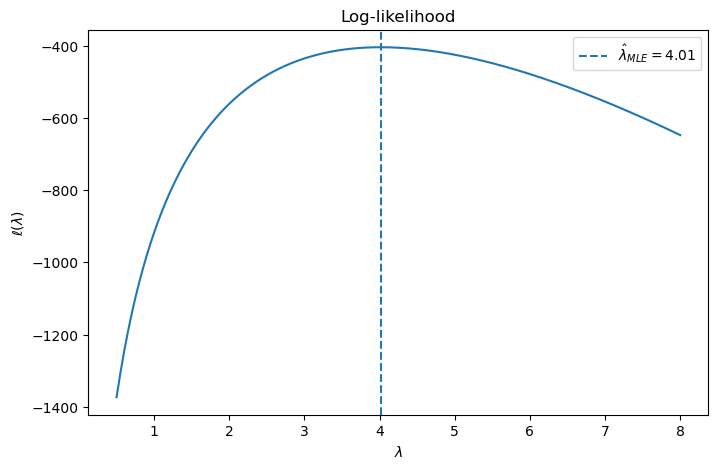

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(candidate_lambdas, logL)
plt.axvline(lambda_hat, linestyle="--",
            label=fr"$\hat\lambda_{{MLE}}={lambda_hat:.2f}$")
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\ell(\lambda)$")
plt.title("Log-likelihood")
plt.legend()
plt.show()



For the Poisson model,
$$
\ell(\lambda)
=
\left(\sum_{i=1}^n x_i\right)\log\lambda
-
n\lambda
-
\sum_{i=1}^n\log(x_i!).
$$

Differentiating,
$$
\frac{d\ell}{d\lambda}
=
\frac{1}{\lambda}\sum_{i=1}^n x_i-n.
$$

Setting this equal to zero gives
$$
\boxed{
\widehat\lambda_{\mathrm{MLE}}
=
\frac1n\sum_{i=1}^n x_i
=
\bar x.
}
$$

For the Poisson distribution, this happens to be the same estimator obtained by the method of moments.



## 4. Maximum likelihood as optimization

In practice, we often work with the **negative log-likelihood**
$$
\mathrm{NLL}(\theta)
=
-\ell(\theta),
$$
and solve
$$
\widehat\theta_{\mathrm{MLE}}
=
\arg\min_\theta \mathrm{NLL}(\theta).
$$

This is the form that appears throughout numerical optimization and machine learning.


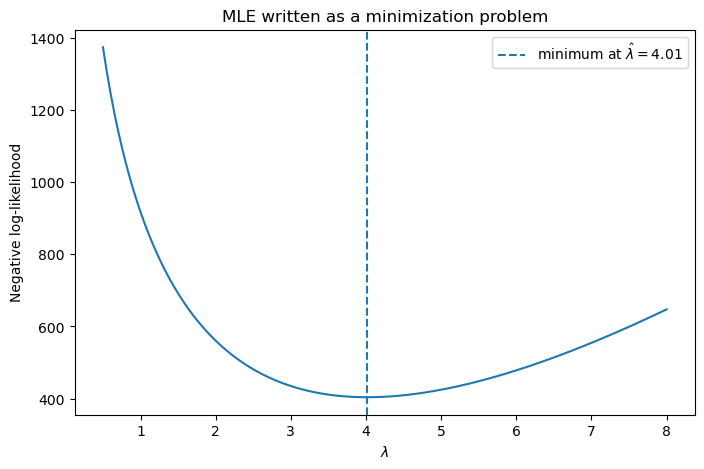

In [11]:

nll = -logL

plt.figure(figsize=(8, 5))
plt.plot(candidate_lambdas, nll)
plt.axvline(lambda_hat, linestyle="--",
            label=fr"minimum at $\hat\lambda={lambda_hat:.2f}$")
plt.xlabel(r"$\lambda$")
plt.ylabel("Negative log-likelihood")
plt.title("MLE written as a minimization problem")
plt.legend()
plt.show()



## 5. More data make the likelihood more concentrated

The MLE is itself a random variable: a different dataset would generally give a different estimate.

As \(n\) increases, the data contain more information about \(\lambda\), and the likelihood typically becomes more sharply concentrated around its maximum.


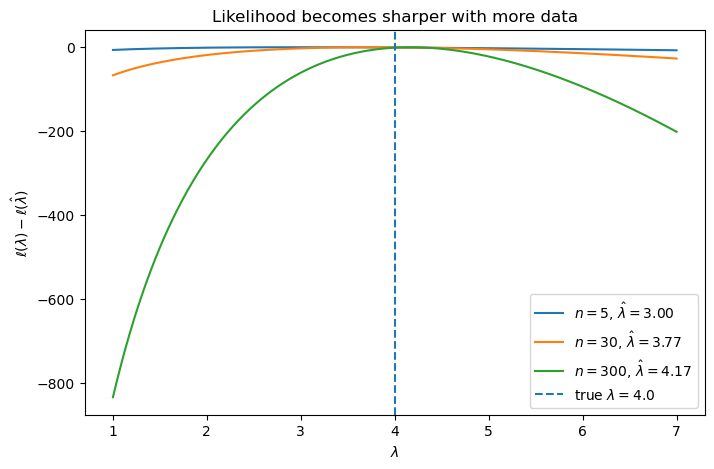

In [12]:

np.random.seed(12)

lambda_true = 4.0
sample_sizes = [5, 30, 300]
lambda_grid = np.linspace(1.0, 7.0, 400)

plt.figure(figsize=(8, 5))

for n_i in sample_sizes:
    x_i = np.random.poisson(lambda_true, size=n_i)
    ll_i = np.array([
        np.sum(poisson.logpmf(x_i, mu=lam))
        for lam in lambda_grid
    ])
    # Plot relative log-likelihood so different sample sizes are comparable.
    ll_i = ll_i - ll_i.max()
    plt.plot(lambda_grid, ll_i, label=fr"$n={n_i}$, $\hat\lambda={x_i.mean():.2f}$")

plt.axvline(lambda_true, linestyle="--", label=fr"true $\lambda={lambda_true}$")
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\ell(\lambda)-\ell(\hat\lambda)$")
plt.title("Likelihood becomes sharper with more data")
plt.legend()
plt.show()



## 6. Repeated experiments: the sampling distribution of the MLE

If we repeatedly collect datasets of size $n$, each experiment produces
$$
\widehat\lambda_{\mathrm{MLE}}=\bar X.
$$

For Poisson data,
$$
\operatorname{Var}(\widehat\lambda_{\mathrm{MLE}})
=
\frac{\lambda}{n},
\qquad
\operatorname{SE}(\widehat\lambda_{\mathrm{MLE}})
=
\sqrt{\frac{\lambda}{n}}.
$$

The simulation below visualizes this repeated-sampling variability.


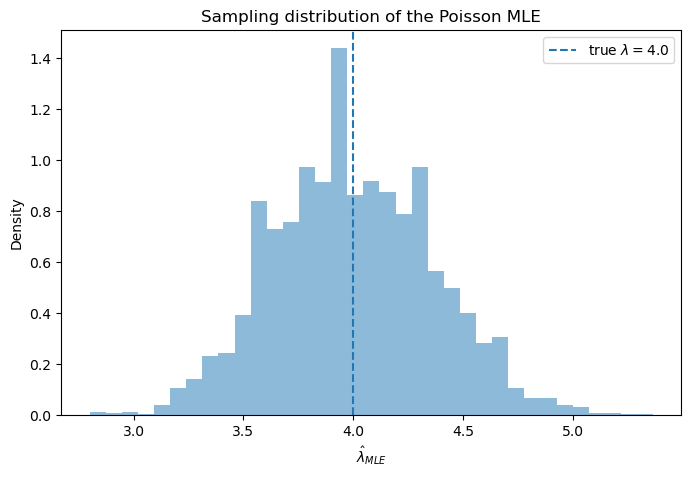

Empirical mean of MLEs: 3.9970
Empirical SD of MLEs:   0.3633
Theoretical SE:         0.3651


In [15]:
np.random.seed(21)

lambda_true = 4.0
n = 30
B = 5000

samples = np.random.poisson(lambda_true, size=(B, n))
lambda_hats = samples.mean(axis=1)

plt.figure(figsize=(8, 5))
plt.hist(lambda_hats, bins=35, density=True, alpha=0.5)
plt.axvline(lambda_true, linestyle="--", label=fr"true $\lambda={lambda_true}$")
plt.xlabel(r"$\hat\lambda_{MLE}$")
plt.ylabel("Density")
plt.title("Sampling distribution of the Poisson MLE")
plt.legend()
plt.show()

print(f"Empirical mean of MLEs: {lambda_hats.mean():.4f}")
print(f"Empirical SD of MLEs:   {lambda_hats.std(ddof=1):.4f}")
print(f"Theoretical SE:         {np.sqrt(lambda_true/n):.4f}")


## Takeaway

Maximum likelihood uses the **full assumed probability model**:
$$
\boxed{
\widehat\theta_{\mathrm{MLE}}
=
\arg\max_\theta
\prod_{i=1}^n p_\theta(x_i)
=
\arg\max_\theta
\sum_{i=1}^n\log p_\theta(x_i).
}
$$

The central picture is simple:

1. fix the observed data;
2. vary the model parameter;
3. evaluate how plausible the data are under each parameter value;
4. choose the parameter at the maximum.

For the Poisson model,
\[
\boxed{\widehat\lambda_{\mathrm{MLE}}=\bar X.}
\]

The important conceptual advance over method of moments is that MLE turns parameter estimation into an **optimization problem**, which extends naturally to models where closed-form estimators are unavailable.
